In [1]:
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt

import config
import constantes
import contraction
import profiles

/Users/baptistesevilla/Documents/Ecole/Physique/Master/M2/Stage Dark matter/Code/profiles.py:225: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integrand, 0.0, np.inf, limit=200, epsrel=epsrel, epsabs=1e-8)


In [2]:
piemd_model = profiles.PIEMD(sigma_0=constantes.SIGMA_0, r_core=constantes.R_CORE, r_cut=constantes.R_CUT)
rho_piemd = piemd_model.density(config.R)

rho_bcm, rho_rdm, rho_baryons, init_comp, m_baryon_f_array, r_f = contraction.contract_Schneider()

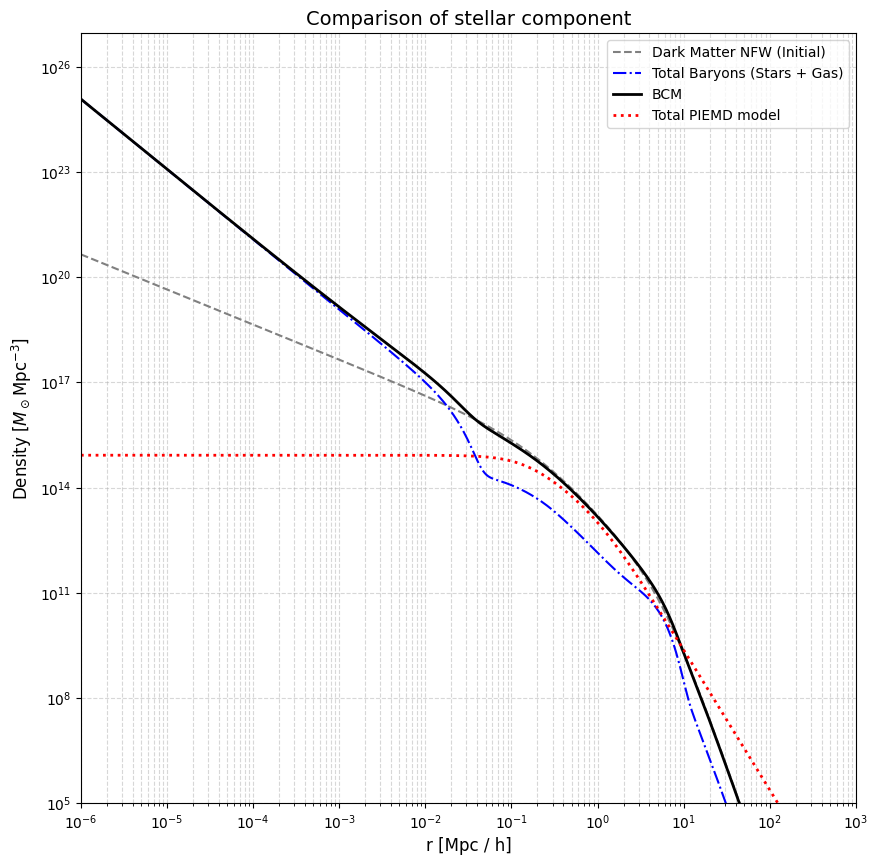

In [3]:
factor = 1.0 / (constantes.H**2)

plt.figure(figsize=(10, 10))
plt.loglog(config.R, init_comp["rho_i_dm"] * factor, label="Dark Matter NFW (Initial)", linestyle='--', color='gray')
plt.loglog(config.R, rho_baryons * factor, label="Total Baryons (Stars + Gas)", linestyle='-.', color='blue')
plt.loglog(config.R, rho_bcm * factor, label="BCM", linewidth=2, color='black')
plt.loglog(config.R, rho_piemd * factor, label="Total PIEMD model", linewidth=2, linestyle=':', color='red')
plt.xlim(1e-6,1e3)
plt.ylim(1e5) 
plt.xlabel('r [Mpc / h]', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{Mpc}^{-3}$]', fontsize=12)
plt.title('Comparison of stellar component', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
